# 머신러닝 과제 2 · 문구류 객체 탐지와 추적 (2차 실험)

스테이플러, 딱풀, 테이프 디스펜서를 탐지하도록 COCO 사전학습 YOLO11n을 미세조정합니다. 검증 세트로 가중치를 선택하고, 테스트 세트의 탐지 성능과 별도 시연 영상의 추적 결과를 확인합니다.

## 1. 실행 환경과 Drive 연결

In [1]:
%pip -q install "ultralytics==8.3.228" "lap>=0.5.12,<1"

In [2]:
import shutil
import subprocess
import tempfile
from collections import Counter, defaultdict
from pathlib import Path
from zipfile import ZipFile

import cv2
import pandas as pd
import torch
import ultralytics
import yaml
from google.colab import drive
from IPython.display import Image as NotebookImage, Video, display
from ultralytics import YOLO

if not torch.cuda.is_available():
    raise RuntimeError("런타임 유형을 GPU로 바꾼 뒤 처음부터 다시 실행하세요.")
if not shutil.which("ffmpeg"):
    raise RuntimeError("이 런타임에서 ffmpeg를 찾을 수 없습니다.")
print("GPU:", torch.cuda.get_device_name(0), "| PyTorch:", torch.__version__,
      "| Ultralytics:", ultralytics.__version__)

drive.mount("/content/drive")
ROOT = Path("/content/drive/MyDrive/ml-hw2-yolo-stationery")
ZIP = ROOT / "data/stationery-yolo-final.zip"
SOURCE_VIDEO = ROOT / "demo/시연영상.mp4"
for path in (ZIP, SOURCE_VIDEO):
    if not path.is_file():
        raise FileNotFoundError(f"Drive에서 파일명과 위치를 확인하세요: {path}")
RUNS = ROOT / "runs"
RUNS.mkdir(exist_ok=True)
WORK = Path(tempfile.mkdtemp(prefix="stationery_", dir="/content"))
print("입력 파일 확인 완료")

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
GPU: NVIDIA L4 | PyTorch: 2.14.1+cu130 | Ultralytics: 8.3.228
Mounted at /content/drive
입력 파일 확인 완료


## 2. 데이터셋 준비

ZIP을 런타임 디스크에 풀고, Roboflow의 상대 경로를 현재 위치에 맞춥니다.

In [3]:
dataset = WORK / "dataset"
with ZipFile(ZIP) as archive:
    archive.extractall(dataset)

config = yaml.safe_load((dataset / "data.yaml").read_text(encoding="utf-8"))
names = config["names"]
assert names == ["glue_stick", "stapler", "tape_dispenser"], names
config.update(path=str(dataset), train="train/images", val="valid/images", test="test/images")
DATA = dataset / "data.yaml"
DATA.write_text(yaml.safe_dump(config, allow_unicode=True, sort_keys=False), encoding="utf-8")

totals = Counter()
for split, expected in [("train", 80), ("valid", 20), ("test", 20)]:
    images = {p.stem for p in (dataset / split / "images").glob("*.jpg")}
    labels = {p.stem: p for p in (dataset / split / "labels").glob("*.txt")}
    assert len(images) == expected and images == set(labels), f"{split} 이미지·라벨 확인 필요"
    counts = Counter()
    for label in labels.values():
        rows = label.read_text().splitlines()
        assert rows, f"빈 라벨: {label.name}"
        for row in rows:
            cls, x, y, w, h = row.split()
            cls = int(cls)
            assert 0 <= cls < len(names) and all(0 <= float(v) <= 1 for v in (x, y, w, h))
            assert float(w) > 0 and float(h) > 0
            counts[names[cls]] += 1
    totals.update(counts)
    print(f"{split}: {len(images)}장, 상자 {sum(counts.values())}개", dict(counts))
assert all(totals[name] == 60 for name in names), totals

train: 80장, 상자 120개 {'tape_dispenser': 40, 'stapler': 40, 'glue_stick': 40}
valid: 20장, 상자 30개 {'stapler': 10, 'glue_stick': 10, 'tape_dispenser': 10}
test: 20장, 상자 30개 {'stapler': 10, 'glue_stick': 10, 'tape_dispenser': 10}


## 3. 2차 파인튜닝
검증 데이터로만 가중치를 선택합니다. 작은 데이터셋에서 첫 실험보다 완만하게 학습하도록 AdamW, 초기 학습률 0.001, 코사인 감소, 최대 80 epoch를 사용합니다. 조기 종료 여유는 30 epoch로 두고 모자이크 비율은 0.25로 줄였습니다. 학습 후 시연 신뢰도 0.25에서 검증 결과를 먼저 확인합니다.

New https://pypi.org/project/ultralytics/8.4.218 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.3.228 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
engine/trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/content/stationery_gi3w76m2/dataset/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=80, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=0.25, multi_scale=False, name=yolo11n_round2, nbs

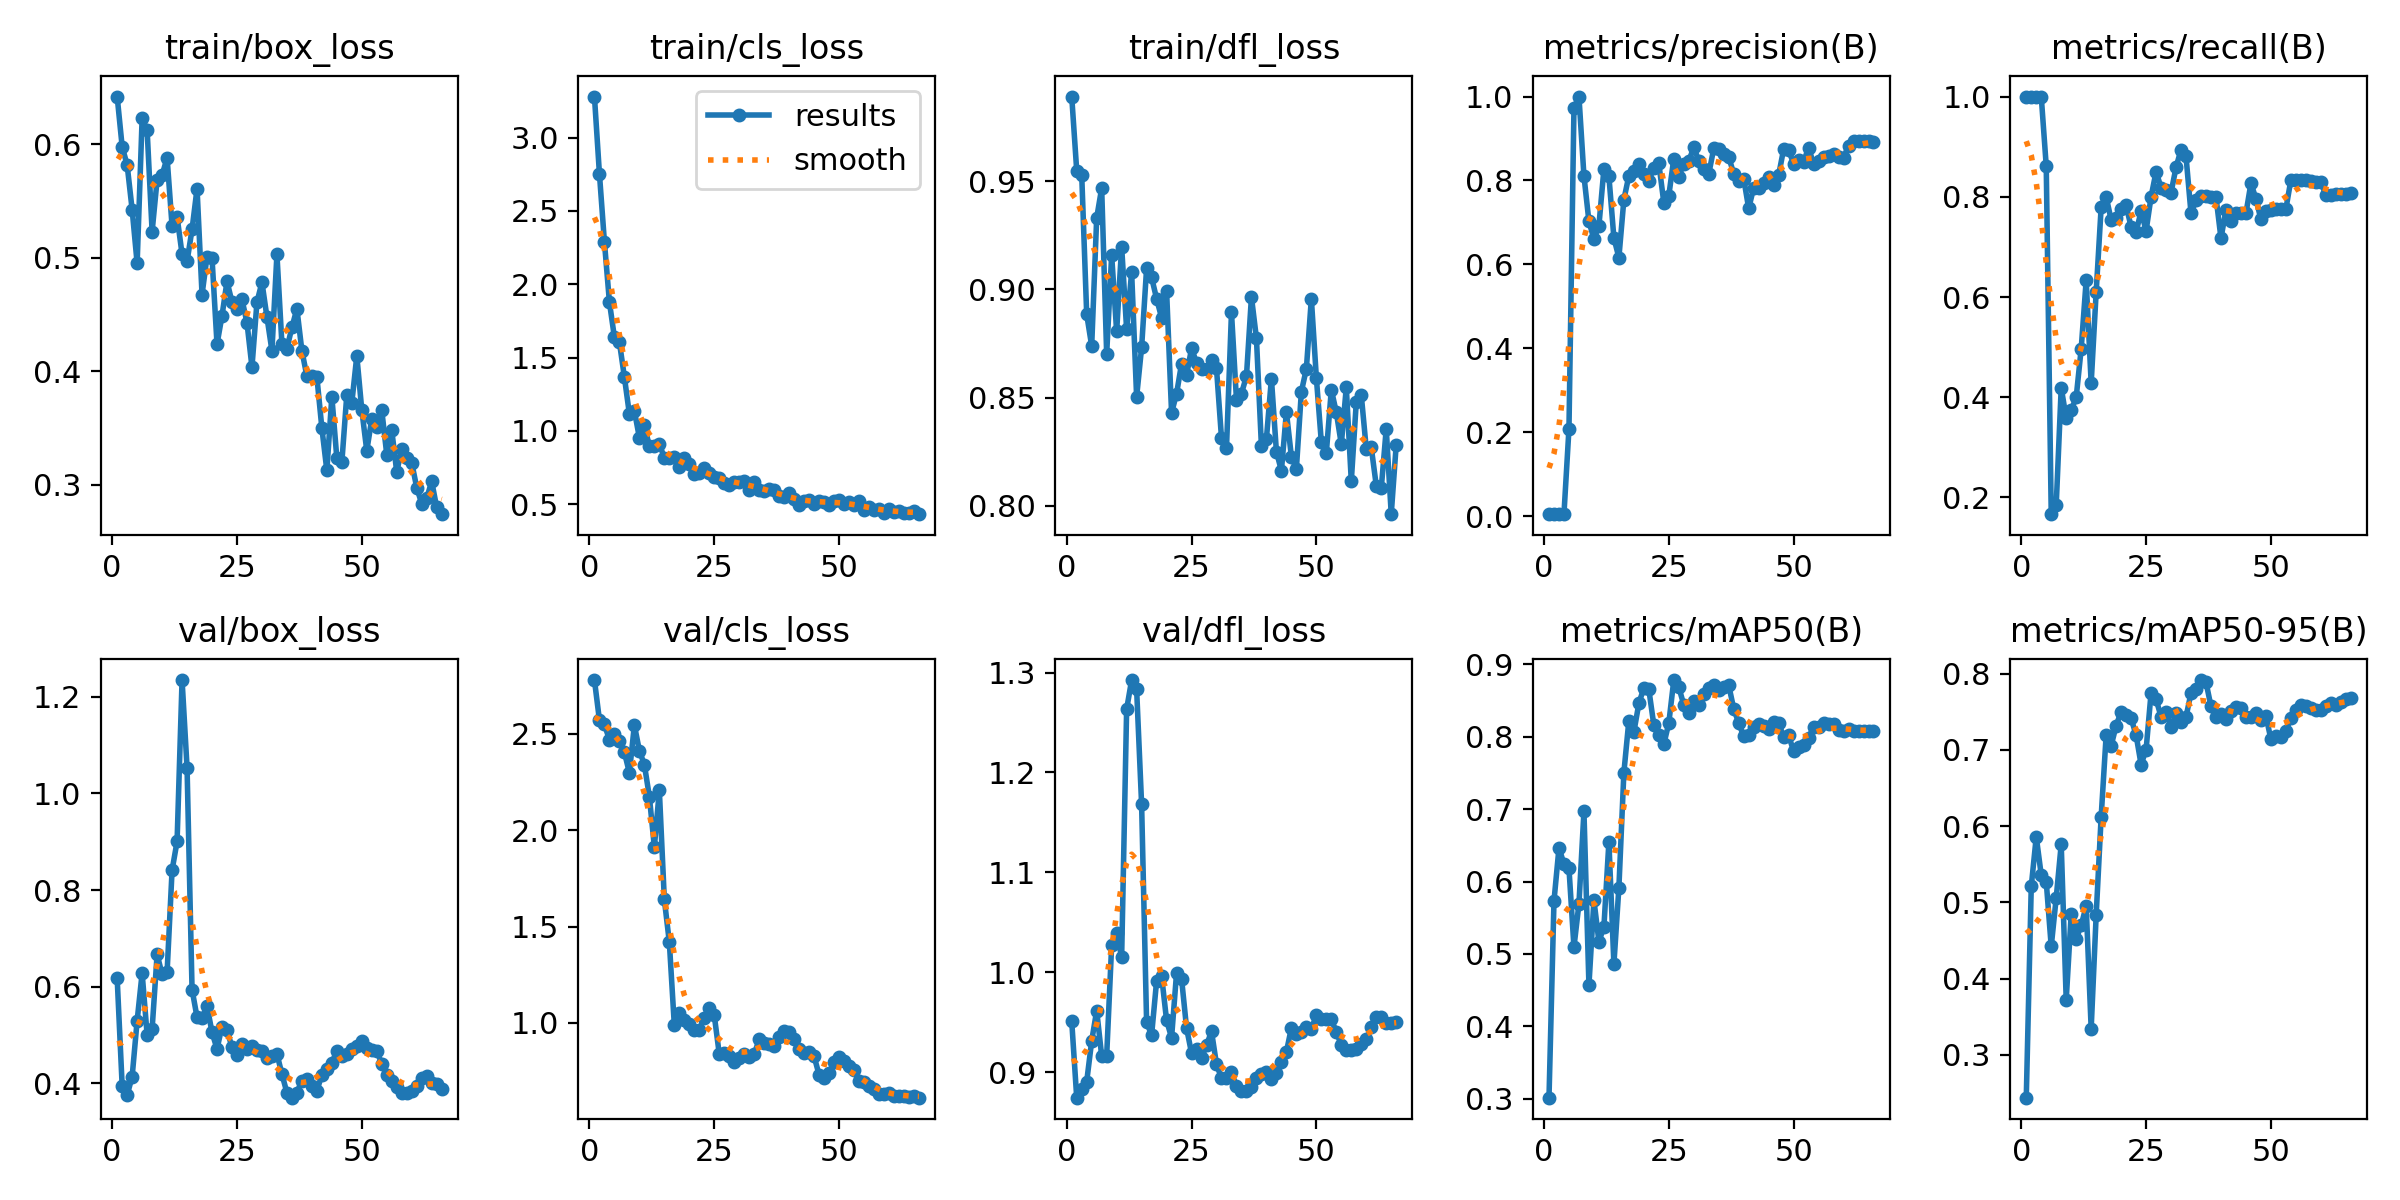

In [4]:
model = YOLO("yolo11n.pt")
model.train(
    data=str(DATA), epochs=80, patience=30, imgsz=640, batch=8,
    optimizer="AdamW", lr0=0.001, cos_lr=True, mosaic=0.25,
    device=0, workers=2, seed=42, plots=True, save=True,
    project=str(RUNS), name="yolo11n_round2", exist_ok=False,
)
run_dir = Path(model.trainer.save_dir)
best = run_dir / "weights/best.pt"
assert best.is_file(), best
print("이번 실행 폴더:", run_dir)
print("선택된 가중치:", best)
if (run_dir / "results.png").is_file():
    display(NotebookImage(filename=str(run_dir / "results.png"), width=900))

### 시연 기준으로 검증 사진 점검
검증 사진 20장을 conf=0.25로 예측합니다. 각 이미지에서 같은 클래스끼리 IoU 0.5 이상일 때 신뢰도 순서로 정답과 일대일 매칭하여 Precision과 Recall을 계산합니다. 이는 추적기 적용 전의 탐지 성능입니다. 혼합 검증 사진 한 장도 표시합니다.

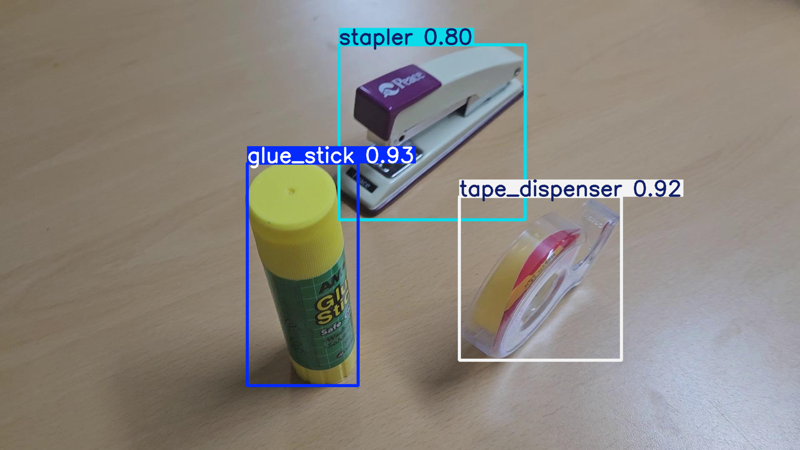

,부류,정답,예측,적중,Precision,Recall
0,glue_stick,10,16,8,0.500,0.8
1,stapler,10,8,7,0.875,0.7
2,tape_dispenser,10,11,10,0.909,1.0


In [5]:
from torchvision.ops import box_iou
from PIL import Image as PILImage

probe = YOLO(str(best))
counts = {i: Counter() for i in range(len(names))}
samples = sorted((dataset / "valid/images").glob("*.jpg"))
shown = False
for path in samples:
    result = probe.predict(str(path), conf=0.25, imgsz=640, device=0, verbose=False)[0]
    labels = (dataset / "valid/labels" / (path.stem + ".txt")).read_text().splitlines()
    truth = []
    for row in labels:
        cid, x, y, w, h = map(float, row.split())
        truth.append((int(cid), [x-w/2, y-h/2, x+w/2, y+h/2]))
        counts[int(cid)]["정답"] += 1
    matched = set()
    boxes = result.boxes.cpu()
    for j in boxes.conf.argsort(descending=True).tolist():
        cid = int(boxes.cls[j])
        counts[cid]["예측"] += 1
        candidates = [k for k, (label, _) in enumerate(truth) if k not in matched and label == cid]
        if candidates:
            ious = box_iou(boxes.xyxyn[j:j+1], torch.tensor([truth[k][1] for k in candidates]))
            value, pos = ious[0].max(dim=0)
            if value.item() >= 0.5:
                matched.add(candidates[pos.item()])
                counts[cid]["적중"] += 1
    if not shown and "_mixed_" in path.name:
        preview = PILImage.fromarray(result.plot()[:, :, ::-1])
        preview.thumbnail((800, 800))
        display(preview)
        shown = True

report = []
for cid, row in counts.items():
    report.append([names[cid], row["정답"], row["예측"], row["적중"],
                   row["적중"] / max(1, row["예측"]), row["적중"] / max(1, row["정답"])])
fixed_scores = pd.DataFrame(report, columns=["부류", "정답", "예측", "적중", "Precision", "Recall"])
display(fixed_scores.round(3))
fixed_scores.to_csv(run_dir / "validation_conf025.csv", index=False, encoding="utf-8-sig")

## 4. 테스트 20장의 탐지 성능

선택된 `best.pt`를 다시 불러와 테스트 세트만 평가합니다. 출력 표의 AP50과 AP50–95는 개별 클래스의 AP이며, 전체 행은 클래스 평균인 mAP입니다.

Ultralytics 8.3.228 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
YOLO11n summary (fused): 100 layers, 2,582,737 parameters, 0 gradients, 6.3 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2349.1±1061.5 MB/s, size: 115.4 KB)
val: Scanning /content/stationery_gi3w76m2/dataset/test/labels... 20 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 20/20 1.4Kit/s 0.0s
val: New cache created: /content/stationery_gi3w76m2/dataset/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 3/3 4.9it/s 0.6s
                   all         20         30      0.963          1      0.995      0.965
            glue_stick         10         10      0.994          1      0.995      0.969
               stapler         10         10      0.908          1      0.995      0.975
        tape_dispenser         10         10      0.986          1      0.995      0.949
Speed: 2.8ms preprocess, 9.6ms inference, 0.0

,부류,Precision,Recall,AP50,AP50-95
0,전체,0.9626,1.0,0.995,0.9646
1,glue_stick,0.9944,1.0,0.995,0.9693
2,stapler,0.9077,1.0,0.995,0.9751
3,tape_dispenser,0.9857,1.0,0.995,0.9494


val_batch0_labels.jpg


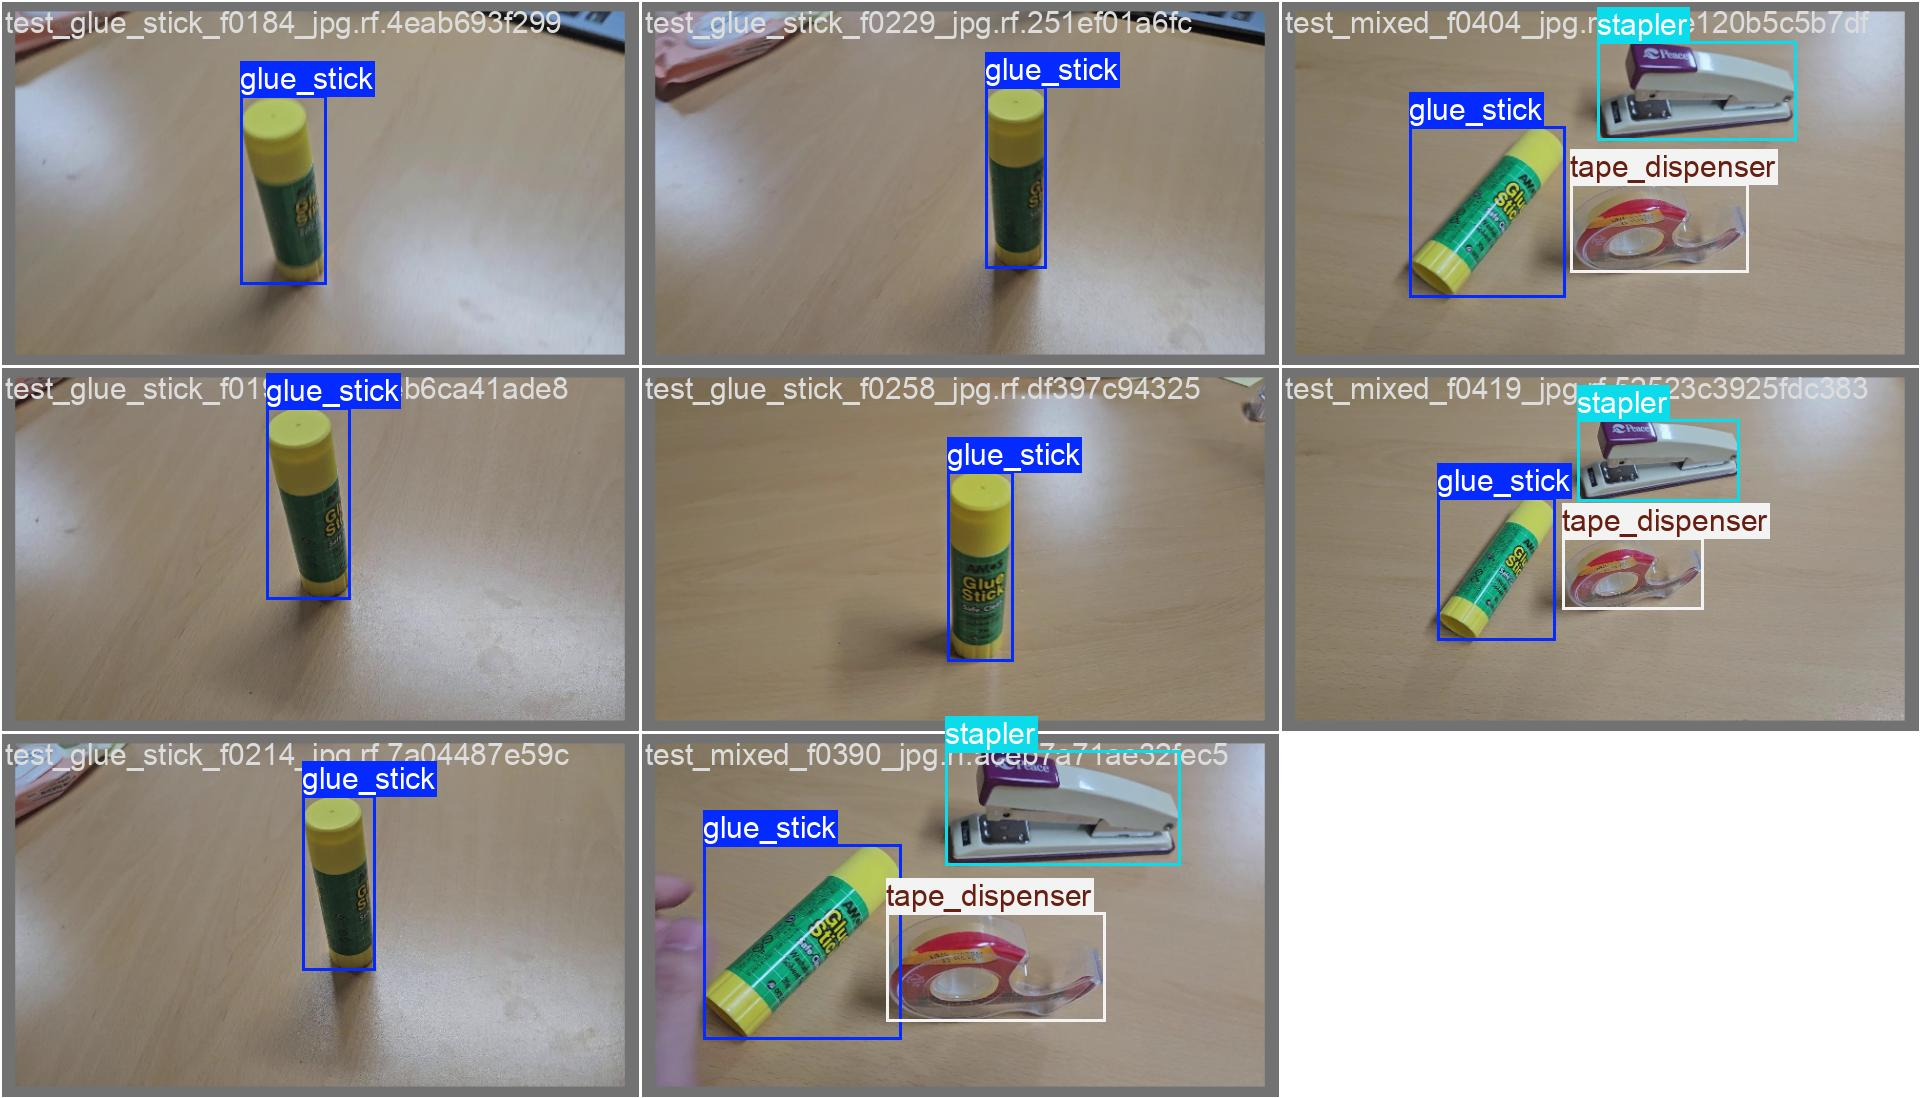

val_batch0_pred.jpg


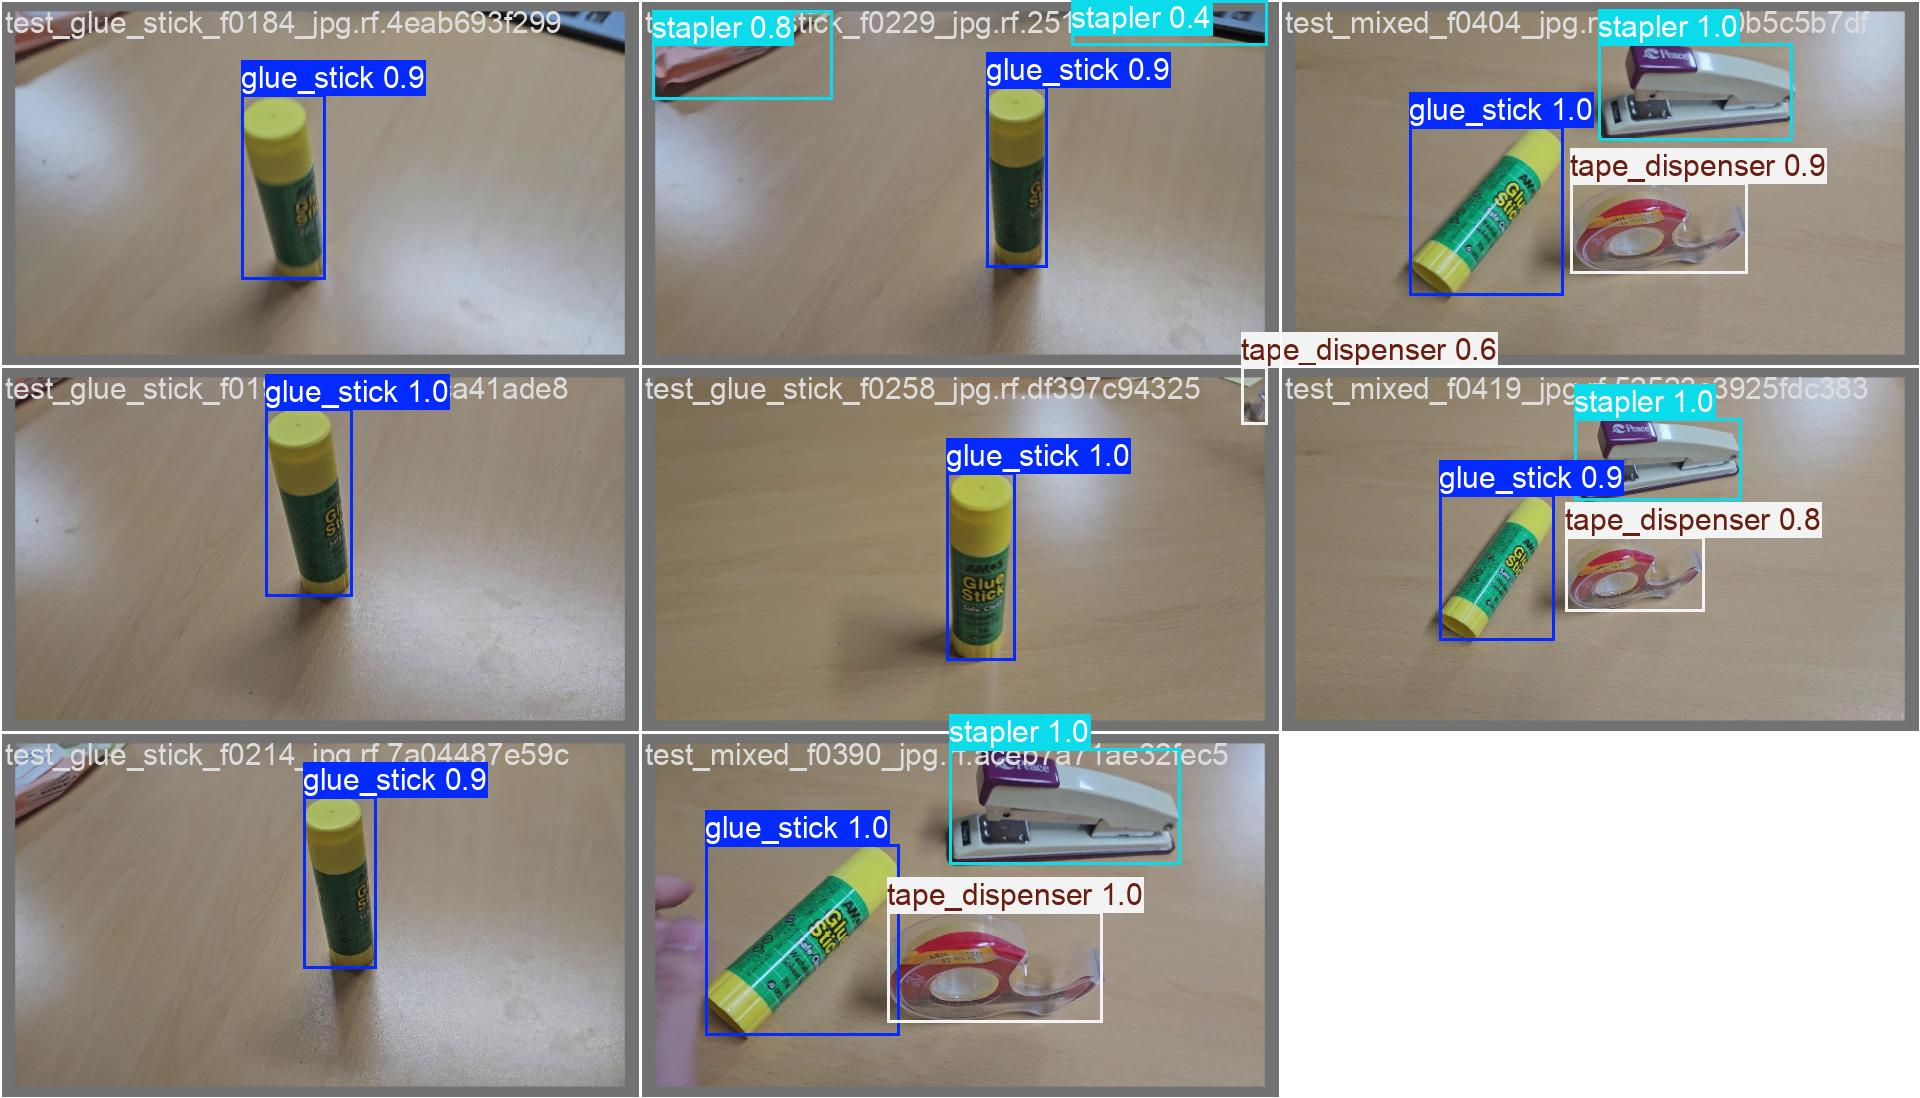

In [6]:
detector = YOLO(str(best))
metrics = detector.val(
    data=str(DATA), split="test", imgsz=640, batch=8, device=0,
    plots=True, project=str(run_dir), name="test", exist_ok=True,
)
rows = [["전체", *metrics.box.mean_results()]]
for index, class_id in enumerate(metrics.box.ap_class_index):
    rows.append([names[int(class_id)], *metrics.box.class_result(index)])
table = pd.DataFrame(rows, columns=["부류", "Precision", "Recall", "AP50", "AP50-95"])
table.to_csv(run_dir / "test_metrics.csv", index=False, encoding="utf-8-sig")
display(table.round(4))
for filename in ("val_batch0_labels.jpg", "val_batch0_pred.jpg"):
    sample = run_dir / "test" / filename
    if sample.is_file():
        print(filename)
        display(NotebookImage(filename=str(sample), width=750))

## 5. 5초 영상 추적

원본의 처음 5초를 30 fps로 맞춘 후 150프레임을 순서대로 처리합니다. ByteTrack이 붙인 ID를 유지하도록 같은 추적 모델에 매 프레임을 전달합니다.

In [7]:
clip = WORK / "demo_clip.mp4"
subprocess.run([
    "ffmpeg", "-loglevel", "error", "-y", "-i", str(SOURCE_VIDEO),
    "-t", "5", "-vf", "fps=30", "-an", "-c:v", "libx264",
    "-preset", "veryfast", "-crf", "18", str(clip),
], check=True)

tracker = YOLO(str(best))
capture = cv2.VideoCapture(str(clip))
width = int(capture.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(capture.get(cv2.CAP_PROP_FRAME_HEIGHT))
if not capture.isOpened():
    raise RuntimeError("시연 영상을 열 수 없습니다.")
rendered = WORK / "tracked.mp4"
writer = cv2.VideoWriter(str(rendered), cv2.VideoWriter_fourcc(*"mp4v"), 30, (width, height))
frame_count = 0
seen_ids = defaultdict(set)
visible_frames = Counter()
try:
    if not writer.isOpened():
        raise RuntimeError("MP4 영상 쓰기를 시작할 수 없습니다.")
    while True:
        ok, frame = capture.read()
        if not ok:
            break
        result = tracker.track(frame, persist=True, tracker="bytetrack.yaml",
                               conf=0.25, imgsz=640, device=0, verbose=False)[0]
        writer.write(result.plot())
        frame_count += 1
        boxes = result.boxes
        if boxes is not None and boxes.id is not None:
            frame_classes = set()
            for cls, obj_id in zip(boxes.cls.int().tolist(), boxes.id.int().tolist()):
                seen_ids[names[cls]].add(obj_id)
                frame_classes.add(names[cls])
            visible_frames.update(frame_classes)
finally:
    capture.release()
    writer.release()

assert frame_count == 150, f"5초에 필요한 150프레임 중 {frame_count}개를 처리했습니다."
final = WORK / "tracking_5s_round2.mp4"
subprocess.run([
    "ffmpeg", "-loglevel", "error", "-y", "-i", str(rendered), "-an",
    "-c:v", "libx264", "-pix_fmt", "yuv420p", "-movflags", "+faststart", str(final),
], check=True)
shutil.copy2(final, run_dir / final.name)
demo_output = ROOT / "demo" / final.name
shutil.copy2(final, demo_output)
summary = pd.DataFrame([
    {"class": name, "frames_with_id": visible_frames[name], "frames_total": frame_count,
     "ids": str(sorted(seen_ids[name]))} for name in names
])
summary.to_csv(run_dir / "tracking_summary.csv", index=False)
for name in names:
    print(f"{name}: ID가 표시된 프레임 {visible_frames[name]}/150, 등장 ID {sorted(seen_ids[name])}")
print("결과 영상:", demo_output)
display(Video(str(final), embed=True, width=720))

Output hidden; open in https://colab.research.google.com to view.